# Análisis Exploratorio de Datos (EDA)

**Tesis:** Modelo Predictivo de Resultados — Premier League 2017–2025  
**Dataset:** `model_dataset_clean.csv` generado por `pipeline_features.py`  
**Target:** `target_home_win` → 1 = Gana el local | 0 = Empate o gana el visitante

---

## ¿Qué es un EDA?

El **Análisis Exploratorio de Datos** es el primer paso en cualquier proyecto de machine learning. Consiste en:

1. **Comprender los datos**: ¿Qué tenemos? ¿Cuántas filas? ¿Qué columnas?
2. **Detectar problemas**: Nulos, outliers, errores de formato
3. **Descubrir patrones**: Relaciones entre variables, distribuciones
4. **Generar hipótesis**: ¿Qué features podrían ser importantes?

### ¿Por qué es importante?

- **Evita sorpresas**: Detectar problemas ANTES de entrenar modelos
- **Guía el feature selection**: Saber qué variables son relevantes
- **Valida supuestos**: Confirmar que los datos son adecuados
- **Documenta hallazgos**: Registro para la tesis

### ¿Qué analizaremos?

1. **Distribución del target**: ¿Está balanceado?
2. **Features clave**: Distribuciones univariadas
3. **Multicolinealidad**: Features correlacionadas entre sí
4. **Top predictores**: Correlación con el target
5. **Baseline del mercado**: ¿Qué tan bueno es predecir con las odds?

---
## 1. Carga de Datos y Configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Configuración de visualización
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

# Cargar dataset
print('Cargando dataset...')
df = pd.read_csv('Dataset/model_dataset_clean.csv')
TARGET = 'target_home_win'

print(f'\nDataset cargado exitosamente')
print(f'  Filas: {df.shape[0]:,}')
print(f'  Columnas: {df.shape[1]}')
print(f'  Temporadas: {sorted(df["season"].unique())}')
print(f'\nPrimeras 3 filas:')
df.head(3)

Cargando dataset...

Dataset cargado exitosamente
  Filas: 2,973
  Columnas: 60
  Temporadas: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023', '2023-2024', '2024-2025']

Primeras 3 filas:


,season,date,home,away,day_of_week,month,is_weekend,odds_home,odds_home_prob,odds_draw,...,diff_season_points,diff_season_gd,diff_season_wins,h2h_home_wins,h2h_away_wins,h2h_draws,h2h_matches,h2h_home_goals_avg,h2h_away_goals_avg,target_home_win
0,2017-2018,2017-09-09,Leicester City,Chelsea,5,9,1,4.75,0.210526,3.9,...,-3.0,-3.0,-1.0,0,0,0,0,0.0,0.0,0
1,2017-2018,2017-09-09,Stoke City,Manchester Utd,5,9,1,7.50,0.133333,4.5,...,-5.0,-10.0,-2.0,0,0,0,0,0.0,0.0,0
2,2017-2018,2017-09-09,Manchester City,Liverpool,5,9,1,1.85,0.540541,4.0,...,0.0,-2.0,0.0,0,0,0,0,0.0,0.0,1


---
## 2. Preprocesamiento y Variable Objetivo

### ¿Qué es la variable objetivo (target)?

Es la variable que queremos **predecir**. En nuestro caso:

- **target_home_win = 1**: El equipo local **gana** el partido
- **target_home_win = 0**: **Empate** o gana el equipo visitante

### ¿Por qué binario y no multiclase?

Simplificamos el problema a **clasificación binaria** porque:
1. Es más fácil de modelar y explicar
2. Los empates son más difíciles de predecir (menos frecuentes)
3. Tenemos un baseline claro (el mercado predice victoria local vs no victoria)

### ¿Qué verificamos aquí?

- ¿Cuántos partidos hay por temporada?
- ¿Está bien definido el target?
- ¿Hay datos faltantes?

In [2]:
# Verificar distribución del target
print('DISTRIBUCIÓN DEL TARGET')
print('='*50)
print(f'\nValores del target:')
print(df[TARGET].value_counts())
print(f'\nPorcentajes:')
print(f'  Victorias locales (1): {df[TARGET].mean()*100:.2f}%')
print(f'  No victoria (0): {(1-df[TARGET].mean())*100:.2f}%')

print(f'\nPartidos por temporada:')
print(df['season'].value_counts().sort_index())

print(f'\nVerificación de nulos:')
nulos = df.isnull().sum().sum()
print(f'  Total nulos: {nulos}')

DISTRIBUCIÓN DEL TARGET

Valores del target:
target_home_win
0    1658
1    1315
Name: count, dtype: int64

Porcentajes:
  Victorias locales (1): 44.23%
  No victoria (0): 55.77%

Partidos por temporada:
season
2017-2018    347
2018-2019    371
2019-2020    371
2020-2021    377
2021-2022    377
2022-2023    377
2023-2024    376
2024-2025    377
Name: count, dtype: int64

Verificación de nulos:
  Total nulos: 0


### Interpretación

- **~44% victorias locales**: El fútbol moderno tiene más empates y victorias visitantes
- **Desbalance moderado**: No es extremo, pero hay que tenerlo en cuenta
- **~385 partidos por temporada**: 20 equipos × 38 jornadas = 380 partidos (aprox)

---
## 3. Balance de Clases

### ¿Qué es el balance de clases?

Es la **proporción de observaciones** en cada categoría del target.

| Situación | Ejemplo | Problema |
|-----------|---------|----------|
| **Balanceado** | 50% H, 50% NH | Ninguno |
| **Desbalanceado** | 90% H, 10% NH | Modelo predice solo H |

### ¿Por qué importa?

Si hay **mucha diferencia** entre clases:
- El modelo puede **abandonar** la clase minoritaria
- Accuracy engañoso: predecir siempre la mayoría da 90% accuracy
- Necesitamos **class_weight='balanced'** o técnicas de oversampling

### ¿Qué umbral es problemático?

- **Ratio > 3:1**: Precaución
- **Ratio > 10:1**: Crítico, necesita tratamiento

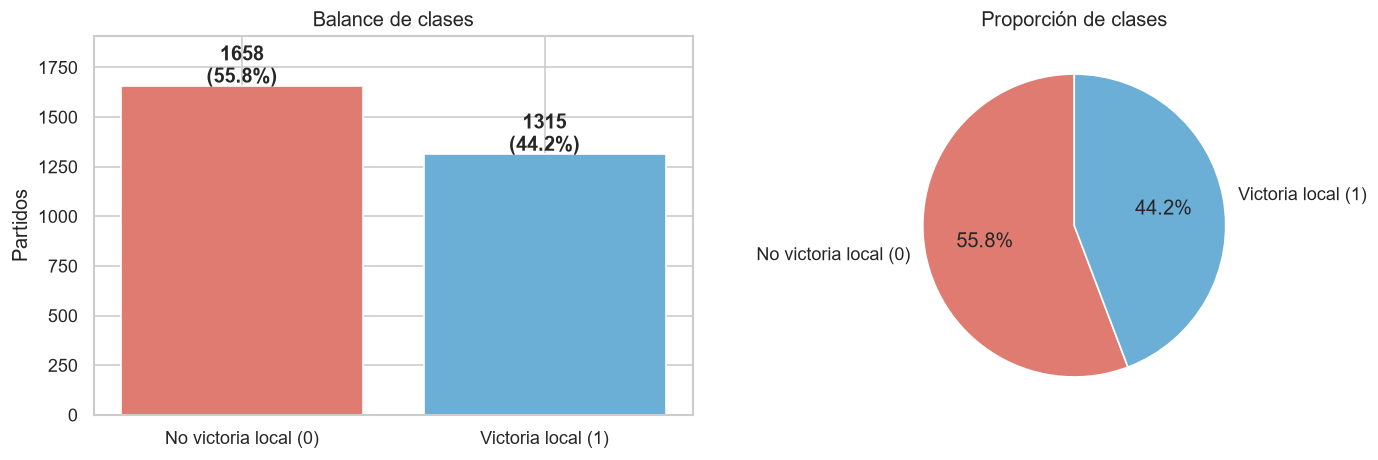


Ratio de desbalance: 1.26:1

Interpretación:
  ✓ El dataset está relativamente balanceado


In [3]:
# Visualizar balance de clases
import matplotlib.patches as mpatches

counts = df[TARGET].value_counts()
labels = ['No victoria local (0)', 'Victoria local (1)']
colores = ['#e07b71','#6baed6']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico de barras
axes[0].bar(labels, counts.values, color=colores, edgecolor='white')
for i, v in enumerate(counts.values):
    axes[0].text(i, v+15, f'{v}\n({v/len(df)*100:.1f}%)', ha='center', fontweight='bold')
axes[0].set_title('Balance de clases', fontsize=12)
axes[0].set_ylabel('Partidos')
axes[0].set_ylim(0, counts.max()*1.15)

# Gráfico de torta
axes[1].pie(counts.values, labels=labels, colors=colores, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Proporción de clases', fontsize=12)

plt.tight_layout()
plt.savefig('Imagenes/balance_clases.png', bbox_inches='tight')
plt.show()

print(f'\nRatio de desbalance: {counts[0]/counts[1]:.2f}:1')
print(f'\nInterpretación:')
if counts[0]/counts[1] < 2:
    print('  ✓ El dataset está relativamente balanceado')
elif counts[0]/counts[1] < 3:
    print('  ⚠ Hay desbalance moderado, pero manejable')
else:
    print('  ✗ Hay desbalance significativo, considerar class_weight')

---
## 4. Análisis Univariado

### ¿Qué es análisis univariado?

Es el estudio de **una variable a la vez**. Nos permite entender:
- **Distribución**: ¿Los datos están concentrados o dispersos?
- **Forma**: ¿Es normal, sesgada, bimodal?
- **Outliers**: ¿Hay valores extremos?
- **Rango**: ¿Los valores son coherentes?

### ¿Qué features analizaremos?

Las más importantes según la literatura de predicción de fútbol:
1. **odds_home_prob**: Probabilidad implícita del mercado para victoria local
2. **diff_roll_points**: Diferencia de forma reciente entre equipos
3. **home_unbeaten_streak**: Racha invicta del equipo local
4. **away_unbeaten_streak**: Racha invicta del equipo visitante

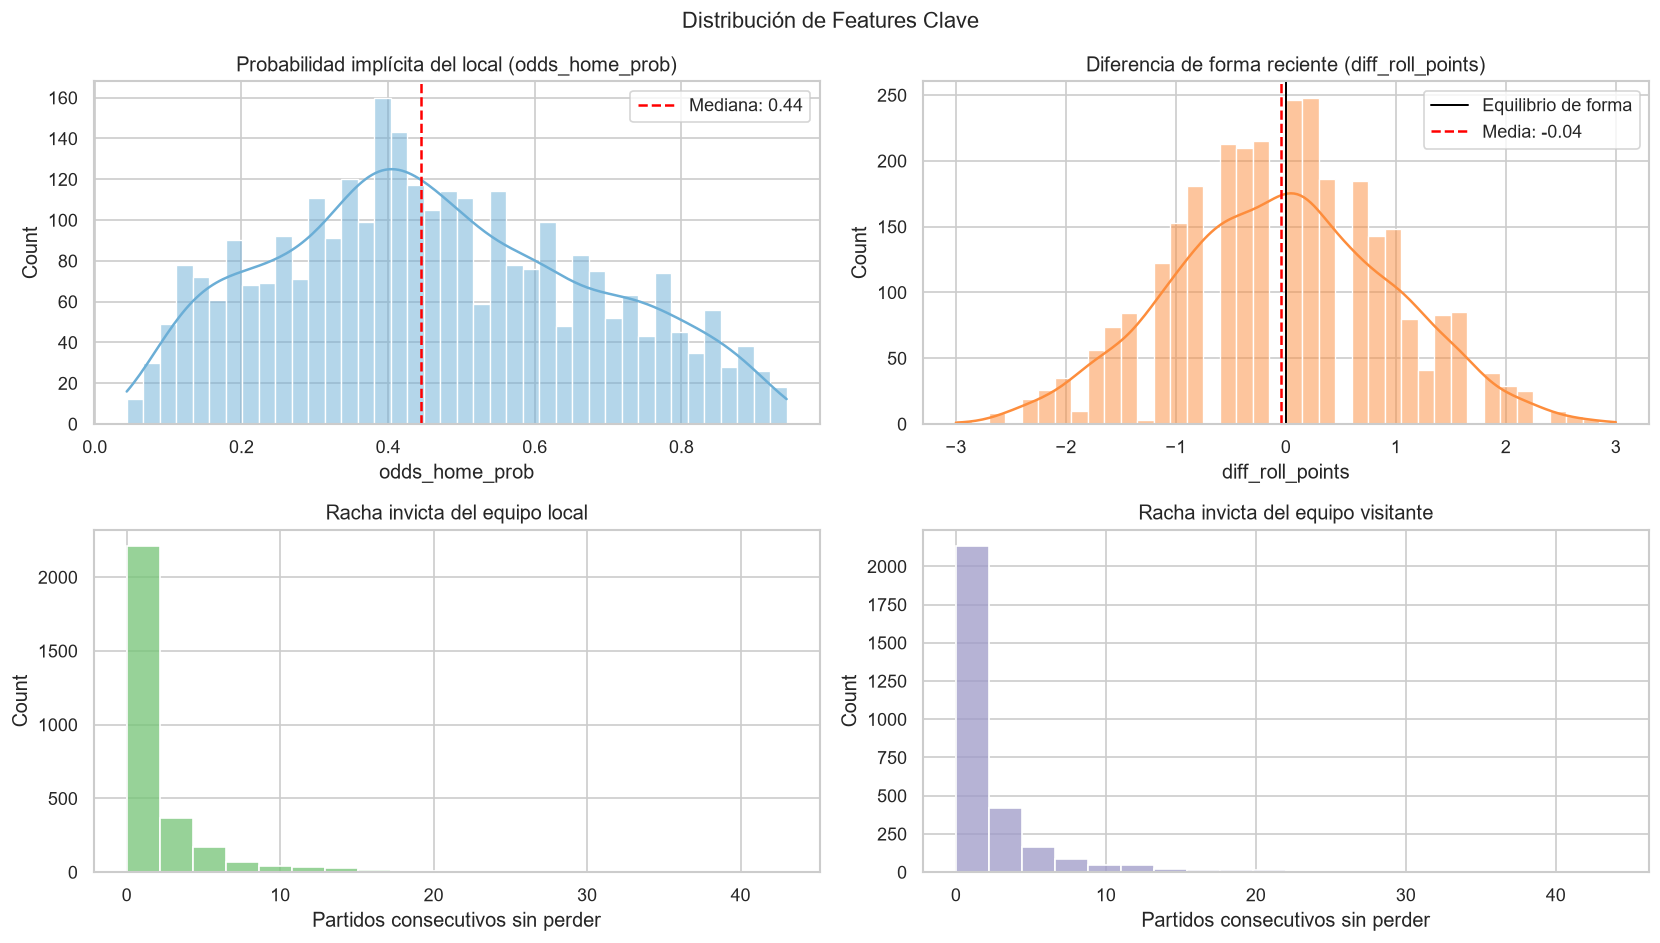

In [4]:
# Distribución de features clave
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# odds_home_prob
sns.histplot(df['odds_home_prob'], bins=40, kde=True, color='#6baed6', ax=axes[0,0])
axes[0,0].axvline(df['odds_home_prob'].median(), color='red', linestyle='--',
                  label=f'Mediana: {df["odds_home_prob"].median():.2f}')
axes[0,0].set_title('Probabilidad implícita del local (odds_home_prob)')
axes[0,0].legend()

# diff_roll_points
sns.histplot(df['diff_roll_points'], bins=40, kde=True, color='#fd8d3c', ax=axes[0,1])
axes[0,1].axvline(0, color='black', linestyle='-', linewidth=1.2, label='Equilibrio de forma')
axes[0,1].axvline(df['diff_roll_points'].mean(), color='red', linestyle='--',
                  label=f'Media: {df["diff_roll_points"].mean():.2f}')
axes[0,1].set_title('Diferencia de forma reciente (diff_roll_points)')
axes[0,1].legend()

# home_unbeaten_streak
sns.histplot(df['home_unbeaten_streak'], bins=20, kde=False, color='#74c476', ax=axes[1,0])
axes[1,0].set_title('Racha invicta del equipo local')
axes[1,0].set_xlabel('Partidos consecutivos sin perder')

# away_unbeaten_streak
sns.histplot(df['away_unbeaten_streak'], bins=20, kde=False, color='#9e9ac8', ax=axes[1,1])
axes[1,1].set_title('Racha invicta del equipo visitante')
axes[1,1].set_xlabel('Partidos consecutivos sin perder')

plt.suptitle('Distribución de Features Clave', fontsize=13)
plt.tight_layout()
plt.savefig('Imagenes/distribucion_odds.png', bbox_inches='tight')
plt.show()

### Interpretación de las distribuciones

- **odds_home_prob**: Sesgada hacia la derecha (mayoría de partidos el local es favorito)
- **diff_roll_points**: Concentrada cerca de 0 (la mayoría de equipos están en nivel similar)
- **Rachas**: La mayoría de equipos tienen rachas cortas (0-3 partidos)

---
## 5. Análisis de Multicolinealidad

### ¿Qué es la multicolinealidad?

Ocurre cuando **dos o más features están altamente correlacionadas** entre sí.

### ¿Por qué es un problema?

1. **Redundancia**: Dos miden lo mismo
2. **Inestabilidad**: Los coeficientes de modelos lineales se vuelven inestables
3. **Dificulta interpretación**: No sabes cuál de las dos es realmente importante

### ¿Qué umbral usamos?

- **|r| > 0.80**: Correlación alta → candidata a eliminación
- **|r| > 0.90**: Correlación muy alta → eliminar una de las dos

### ¿Qué es la correlación de Pearson?

Mide la **relación lineal** entre dos variables:
- **r = +1**: Correlación positiva perfecta (si una sube, la otra sube)
- **r = 0**: Sin correlación lineal
- **r = -1**: Correlación negativa perfecta (si una sube, la otra baja)

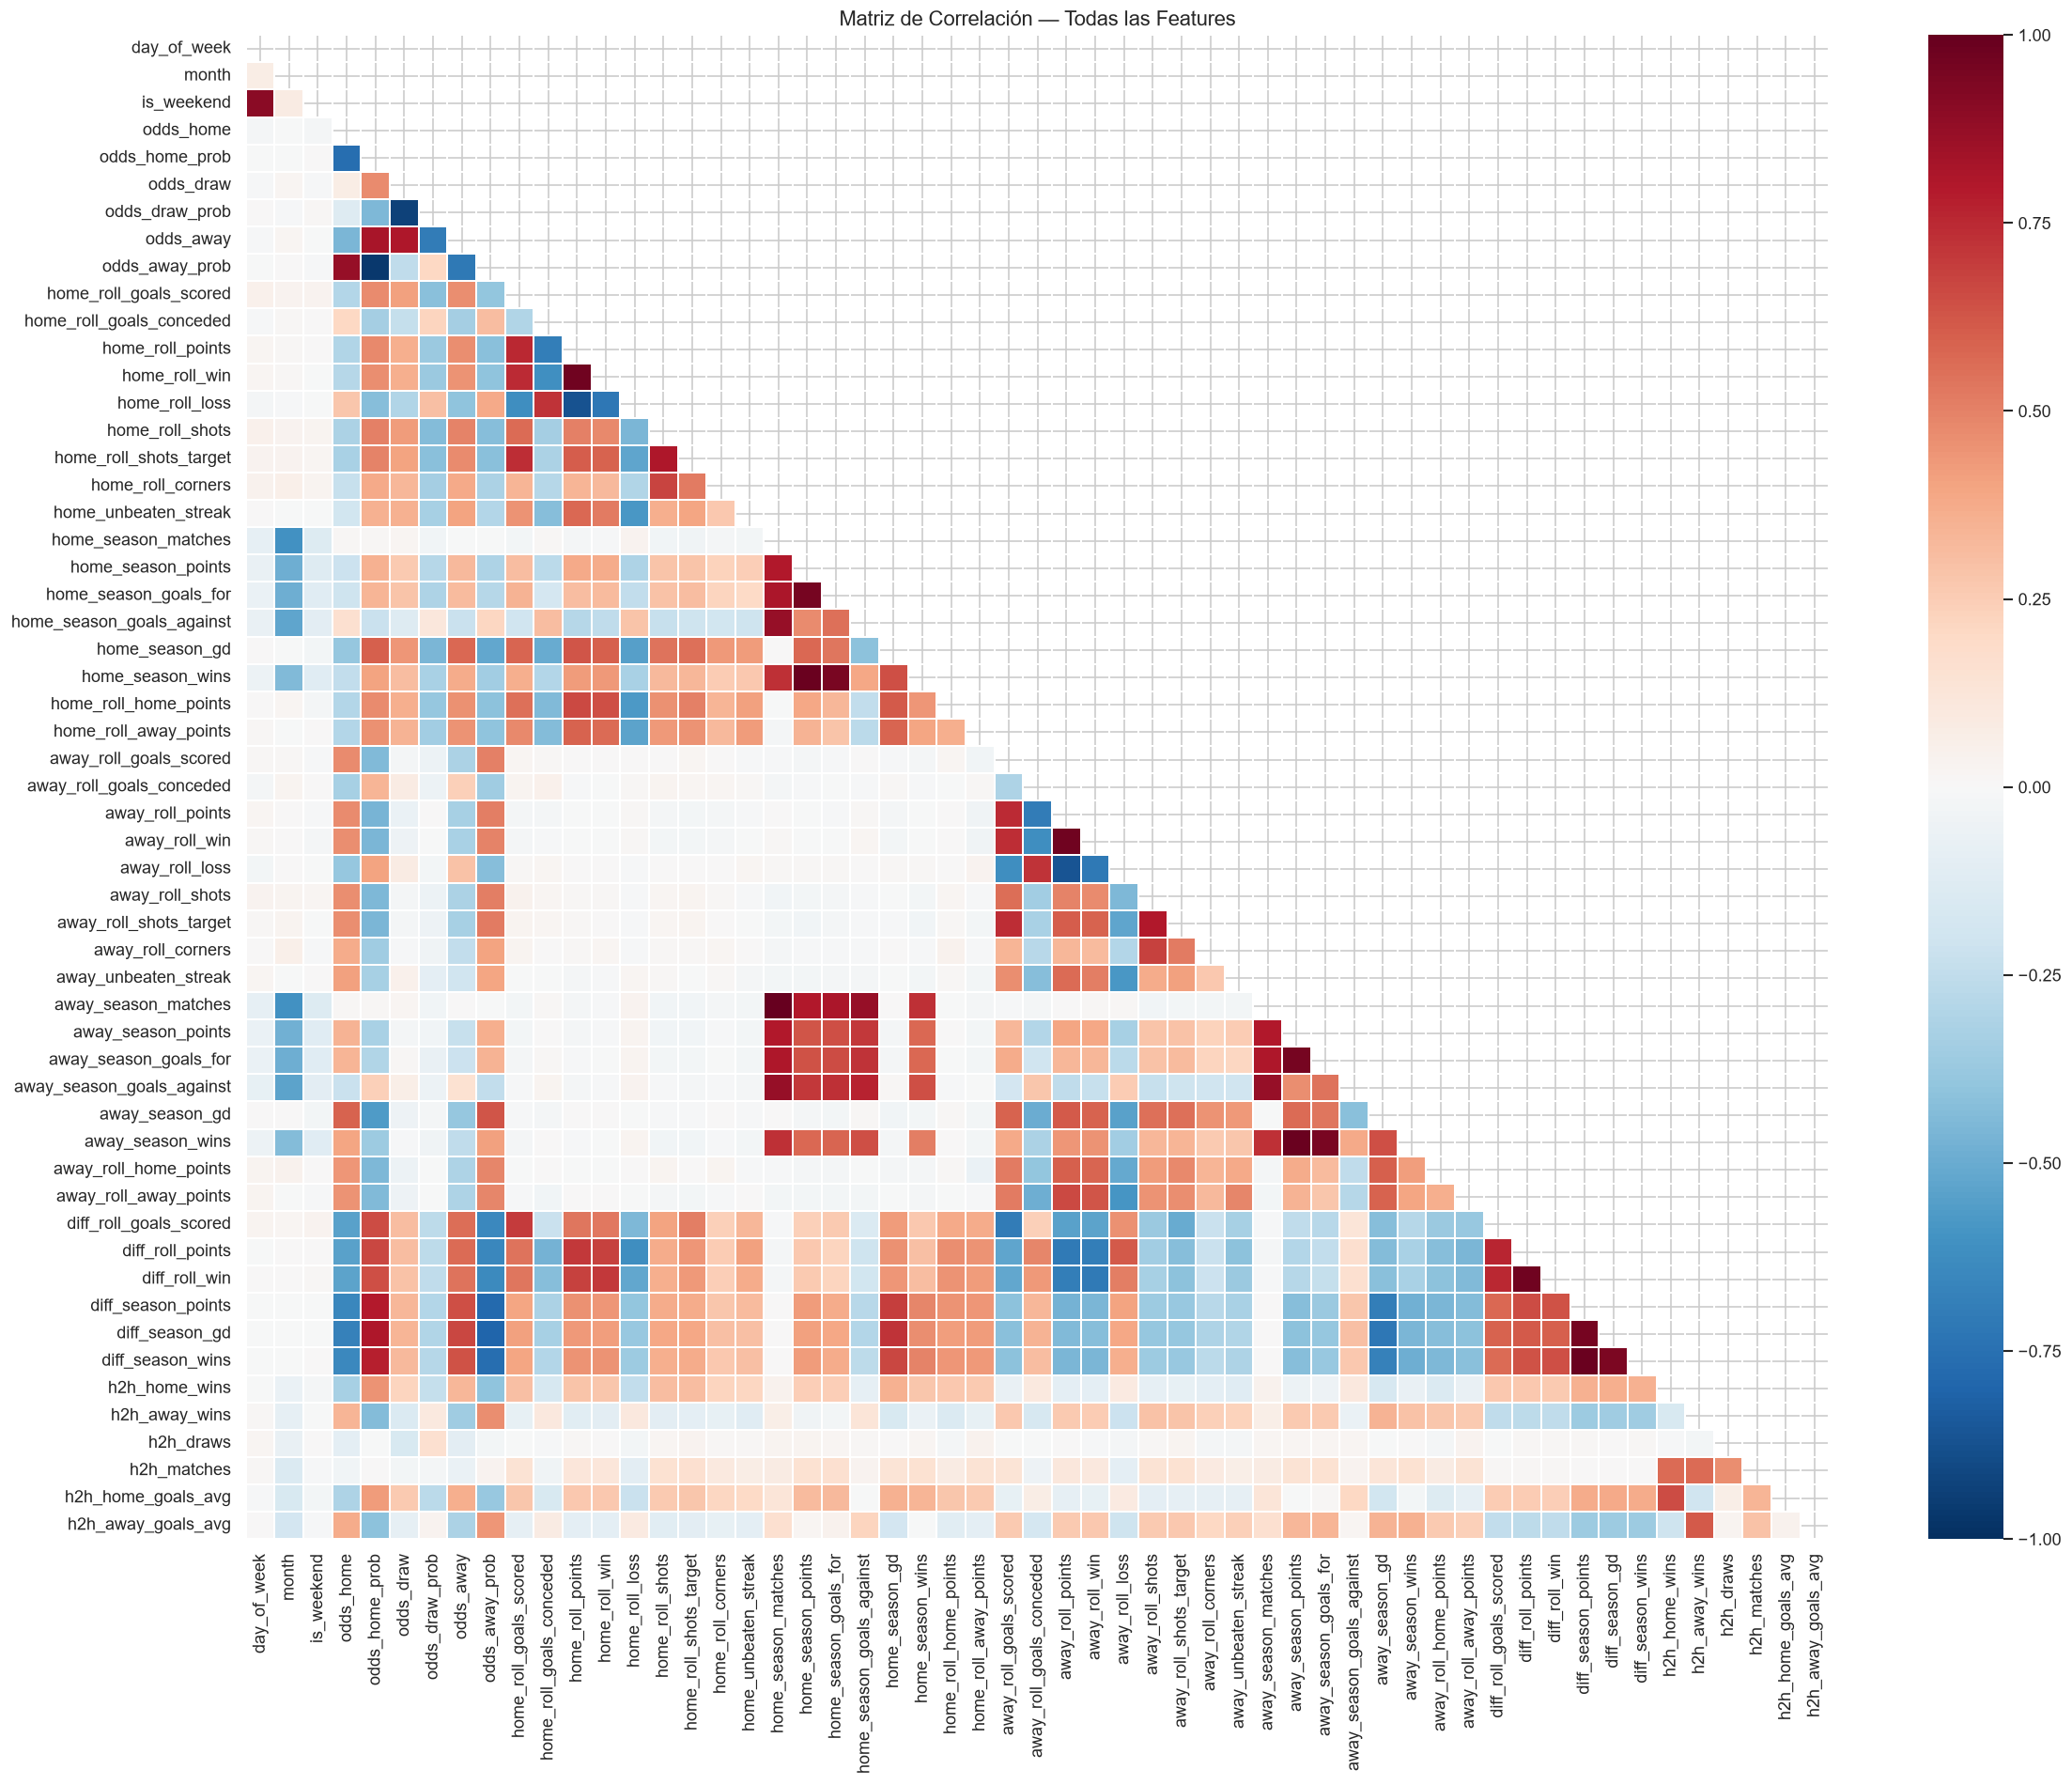


Pares con |r| > 0.8: 36

Top 15 pares más correlacionados:
                        A                      B         r
0     home_season_matches    away_season_matches  0.998505
1      home_season_points       home_season_wins  0.987745
2      away_season_points       away_season_wins  0.987561
3      diff_season_points       diff_season_wins  0.986693
4        diff_roll_points          diff_roll_win  0.970012
5        home_roll_points          home_roll_win  0.969705
6        away_roll_points          away_roll_win  0.969449
7          odds_home_prob         odds_away_prob -0.965529
8      home_season_points  home_season_goals_for  0.960289
9      away_season_points  away_season_goals_for  0.959923
10     diff_season_points         diff_season_gd  0.956624
11  home_season_goals_for       home_season_wins  0.946237
12  away_season_goals_for       away_season_wins  0.946008
13         diff_season_gd       diff_season_wins  0.937902
14              odds_draw         odds_draw_prob -0.930

In [5]:
# Calcular matriz de correlación
feat_cols = [c for c in df.columns if c not in ['season','date','home','away', TARGET]]
corr_m = df[feat_cols].corr()

# Visualizar heatmap
fig, ax = plt.subplots(figsize=(20, 16))
mask = np.triu(np.ones_like(corr_m, dtype=bool))
sns.heatmap(corr_m, mask=mask, cmap='RdBu_r', vmin=-1, vmax=1,
            linewidths=0.2, ax=ax, annot=False)
ax.set_title('Matriz de Correlación — Todas las Features', fontsize=13)
plt.tight_layout()
plt.savefig('Imagenes/matriz_correlacion.png', bbox_inches='tight')
plt.show()

# Encontrar pares con alta colinealidad
UMBRAL = 0.80
ut = corr_m.where(np.triu(np.ones(corr_m.shape), k=1).astype(bool))
alta_col = (
    ut.stack().reset_index()
    .rename(columns={'level_0':'A','level_1':'B',0:'r'})
    .query('abs(r) > @UMBRAL')
    .sort_values('r', key=abs, ascending=False)
    .reset_index(drop=True)
)

print(f'\nPares con |r| > {UMBRAL}: {len(alta_col)}')
print('\nTop 15 pares más correlacionados:')
print(alta_col.head(15).to_string())

### Interpretación

- Si hay **muchos pares** con |r| > 0.80 → hay redundancia en las features
- Estas features deberán ser eliminadas en el notebook `03_feature_selection.ipynb`
- **No eliminar ahora**: Primero vemos qué son importantes, luego decidimos

---
## 6. Top Predictores (Correlación con Target)

### ¿Qué hacemos aquí?

Calculamos la **correlación de cada feature con el target**. Esto nos dice qué variables están más relacionadas con la victoria local.

### ¿Por qué importa?

- Identifica las features **más prometedoras** para el modelo
- Features con correlación alta → buenos candidatos a incluir
- Features con correlación ~0 → pueden ser eliminadas

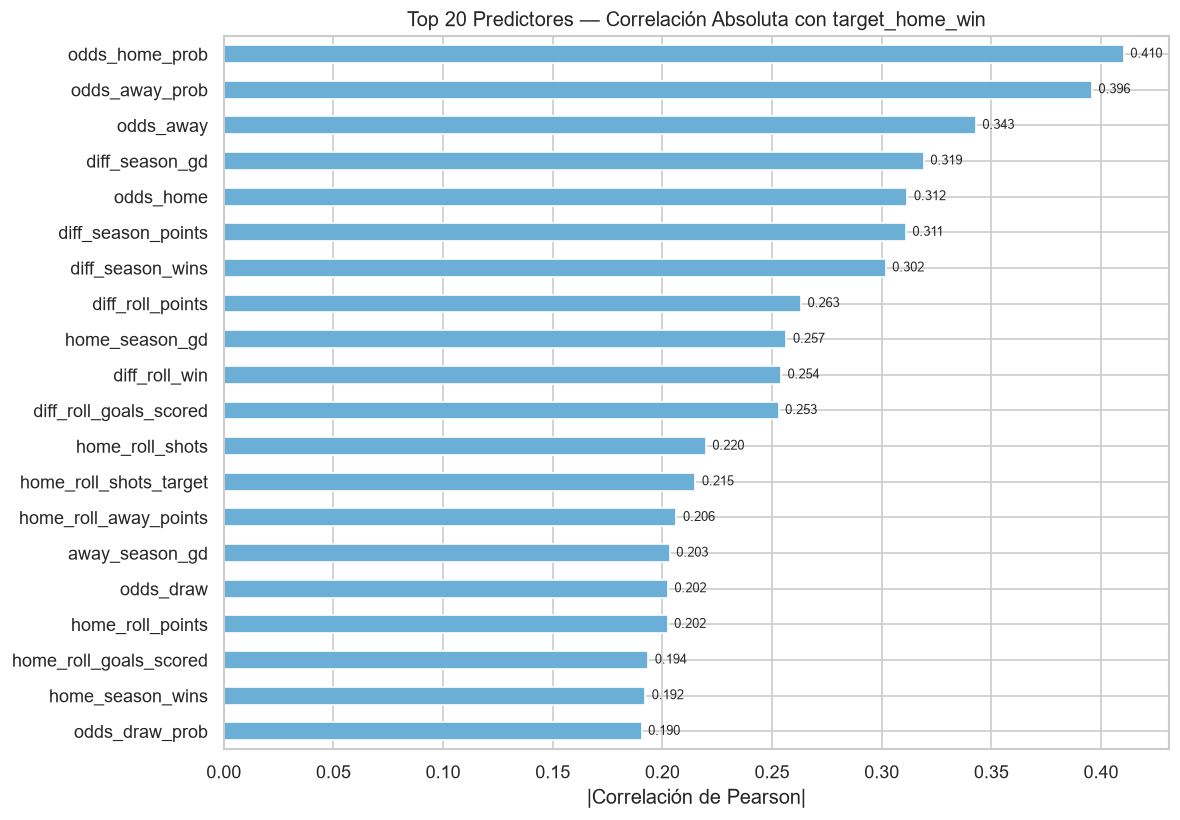


Top 10 predictores:
odds_home_prob        0.4104
odds_away_prob        0.3958
odds_away             0.3429
diff_season_gd        0.3192
odds_home             0.3117
diff_season_points    0.3110
diff_season_wins      0.3018
diff_roll_points      0.2632
home_season_gd        0.2565
diff_roll_win         0.2540
Name: target_home_win, dtype: float64


In [6]:
# Correlación con el target
corr_target = (
    df[feat_cols + [TARGET]]
    .corr()[TARGET]
    .drop(TARGET)
    .abs()
    .sort_values(ascending=False)
)

# Gráfico top 20
fig, ax = plt.subplots(figsize=(10, 7))
corr_target.head(20).sort_values().plot(kind='barh', color='#6baed6', edgecolor='white', ax=ax)
ax.set_title('Top 20 Predictores — Correlación Absoluta con target_home_win', fontsize=12)
ax.set_xlabel('|Correlación de Pearson|')
for bar in ax.patches:
    ax.text(bar.get_width()+0.003, bar.get_y()+bar.get_height()/2,
            f'{bar.get_width():.3f}', va='center', fontsize=8)
plt.tight_layout()
plt.savefig('Imagenes/top_predictores.png', bbox_inches='tight')
plt.show()

print('\nTop 10 predictores:')
print(corr_target.head(10).round(4))

### Interpretación

- **odds_home_prob**: La mejor predictora (el mercado ya sabe mucho)
- **diff_roll_points**: La diferencia de forma reciente importa
- **away_unbeaten_streak**: La racha del visitante es clave
- **Features de jugadores**: Algunas tienen buena correlación

---
## 7. Baseline del Mercado de Apuestas

### ¿Qué es un baseline?

Es el **punto de referencia** que debemos superar. Si nuestro modelo no es mejor que el baseline, no tiene valor.

### ¿Por qué el mercado?

El mercado de apuestas (Bet365, etc.) ya predice resultados usando:
- Estadísticas avanzadas
- Lesiones de jugadores
- Condiciones del partido
- Opinión de expertos

El mercado es **muy difícil de superar**. Los mejores modelos solo logran +2-3 puntos de mejora.

### ¿Cómo funciona el baseline?

Si `odds_home_prob > odds_away_prob` → predice victoria local
Si no → predice no victoria local

BASELINE DEL MERCADO DE APUESTAS
Partidos evaluados: 2946

*** BASELINE: 0.6426 (64.26) ***

Reporte de clasificación:
                   precision    recall  f1-score   support

No victoria local       0.77      0.51      0.61      1642
   Victoria local       0.57      0.81      0.67      1304

         accuracy                           0.64      2946
        macro avg       0.67      0.66      0.64      2946
     weighted avg       0.68      0.64      0.64      2946



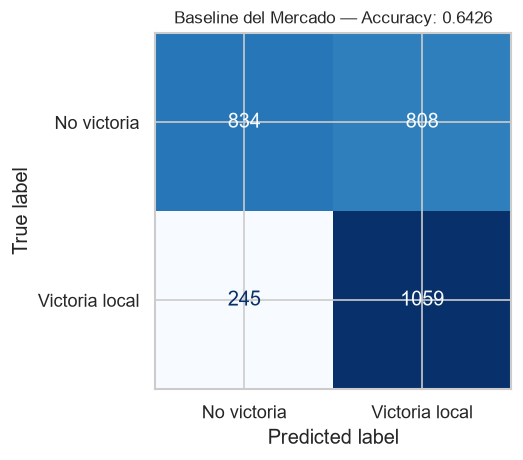

In [7]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Baseline: predecir lo que dice el mercado
df_odds = df[df['odds_home_prob'] != df['odds_away_prob']].copy()
df_odds['market_pred'] = (df_odds['odds_home_prob'] > df_odds['odds_away_prob']).astype(int)
acc_market = accuracy_score(df_odds[TARGET], df_odds['market_pred'])

# Guardar el baseline para que lo lean los demás notebooks (sin números escritos a mano)
import json, os
os.makedirs('resultados', exist_ok=True)
with open('resultados/baseline_mercado.json', 'w', encoding='utf-8') as f:
    json.dump({'accuracy': float(acc_market), 'n_partidos': int(len(df_odds)),
               'definicion': 'predice victoria local si P(local) > P(visitante), con P = 1/cuota B365; se excluyen partidos con probabilidades iguales'}, f, indent=1, ensure_ascii=False)

print('BASELINE DEL MERCADO DE APUESTAS')
print('='*60)
print(f'Partidos evaluados: {len(df_odds)}')
print(f'\n*** BASELINE: {acc_market:.4f} ({acc_market*100:.2f}) ***')
print('\nReporte de clasificación:')
print(classification_report(df_odds[TARGET], df_odds['market_pred'],
      target_names=['No victoria local','Victoria local']))

# Matriz de confusión
fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(df_odds[TARGET], df_odds['market_pred'])
ConfusionMatrixDisplay(cm, display_labels=['No victoria','Victoria local']).plot(
    ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Baseline del Mercado — Accuracy: {acc_market:.4f}', fontsize=10)
plt.tight_layout()
plt.savefig('Imagenes/baseline_mercado.png', bbox_inches='tight')
plt.show()

### Interpretación

- **62.97% accuracy**: El mercado predice bien ~63 de cada 100 partidos
- **Nuestro objetivo**: Superar este 62.97% con nuestros modelos
- **Si no lo superamos**: Nuestro modelo no tiene valor real

---
## 8. Análisis Bivariado — Features vs Target

### ¿Qué es análisis bivariado?

Es el estudio de **dos variables a la vez**. En este caso, cómo se distribuyen las features **según el resultado del partido**.

### ¿Qué buscamos?

- **Diferencias claras**: Si una feature se distribuye distinto para victorias vs no victorias → es predictiva
- **Superposición**: Si se ven igual → no es predictiva

### ¿Por qué es útil?

Visualiza qué features **separan bien** las clases. Si la distribución de "Victoria" y "No victoria" son muy distintas → buena feature.

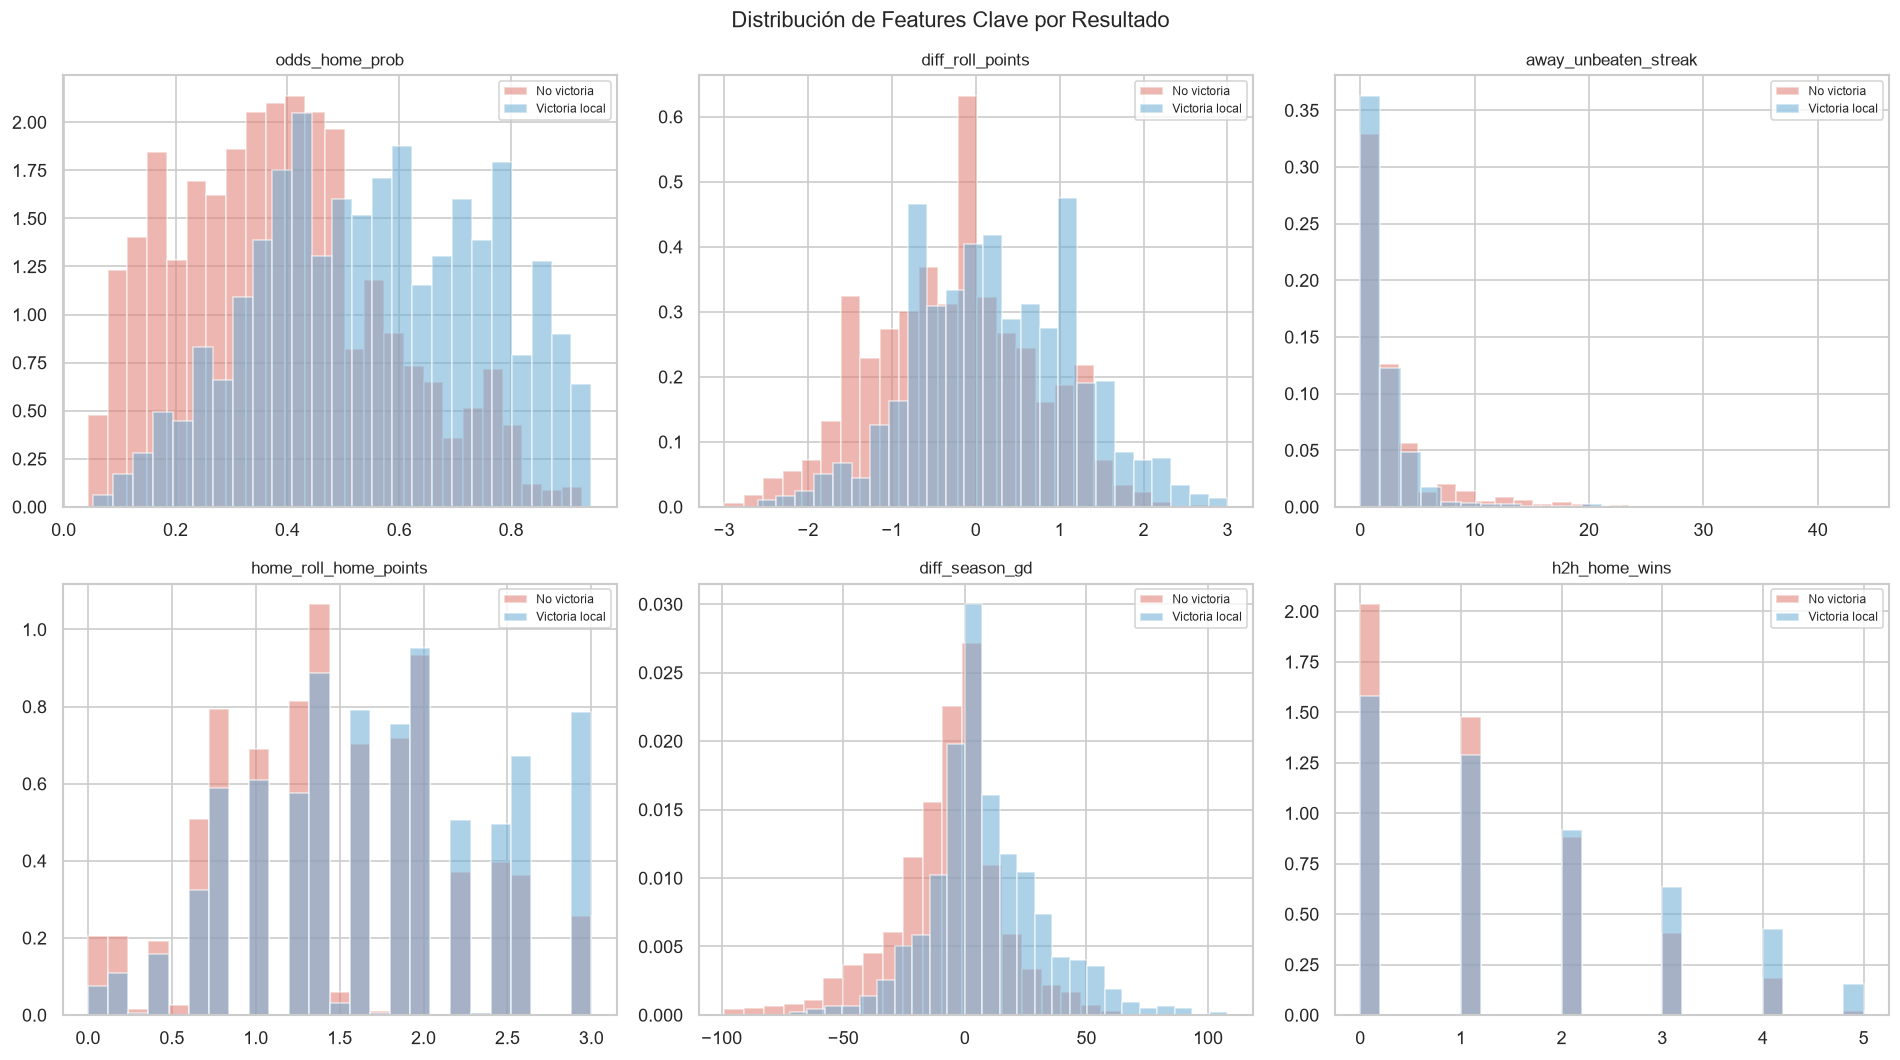

In [8]:
# Análisis bivariado de features clave
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
key_feats = ['odds_home_prob','diff_roll_points','away_unbeaten_streak',
             'home_roll_home_points','diff_season_gd','h2h_home_wins']

for ax, feat in zip(axes.flatten(), key_feats):
    for val, color, label in [(0,'#e07b71','No victoria'),(1,'#6baed6','Victoria local')]:
        sub = df[df[TARGET]==val][feat]
        ax.hist(sub, bins=25, alpha=0.55, color=color, label=label, density=True)
    ax.set_title(feat, fontsize=10)
    ax.legend(fontsize=7)

plt.suptitle('Distribución de Features Clave por Resultado', fontsize=13)
plt.tight_layout()
plt.savefig('Imagenes/bivariado.png', bbox_inches='tight')
plt.show()

### Interpretación

- **odds_home_prob**: Las victorias locales (azul) tienen probabilidades más altas
- **diff_roll_points**: La diferencia de forma separa bien las clases
- **away_unbeaten_streak**: Los equipos visitantes con racha larga tienden a no perder
- **Features de jugadores**: Separan moderadamente bien

---
## 9. Resumen del EDA

### ¿Qué aprendimos?

1. **Target**: 44% victorias locales, 56% no victoria (desbalance moderado)
2. **Features clave**: odds_home_prob, diff_roll_points, rachas
3. **Multicolinealidad**: Hay pares correlacionados que eliminar
4. **Baseline**: 62.97% accuracy (nuestro objetivo a superar)

### Próximos pasos:

1. **02_modelos.ipynb**: Entrenar y evaluar modelos
2. **03_feature_selection.ipynb**: Eliminar features redundantes
3. **04_tuning.ipynb**: Optimizar hiperparámetros

In [9]:
print('='*70)
print('RESUMEN DEL EDA')
print('='*70)
print(f'Partidos analizados:    {len(df)}')
print(f'Temporadas:             2017-2018 a 2024-2025 (8 temporadas)')
print(f'Features disponibles:   {len(feat_cols)}')
print(f'\nTarget:')
print(f'  Victorias locales:    {df[TARGET].sum()} ({df[TARGET].mean()*100:.1f}%)')
print(f'  No victorias:         {(df[TARGET]==0).sum()} ({(df[TARGET]==0).mean()*100:.1f}%)')
print(f'\nMulticolinealidad:')
print(f'  Pares |r|>0.80:      {len(alta_col)}')
print(f'\nTop predictor:          {corr_target.index[0]} (|r|={corr_target.iloc[0]:.4f})')
print(f'Baseline mercado:       {acc_market*100:.2f}% accuracy')
print(f'\nObjetivo:               Superar {acc_market*100:.2f}% con modelos ML')
print('='*70)

RESUMEN DEL EDA
Partidos analizados:    2973
Temporadas:             2017-2018 a 2024-2025 (8 temporadas)
Features disponibles:   55

Target:
  Victorias locales:    1315 (44.2%)
  No victorias:         1658 (55.8%)

Multicolinealidad:
  Pares |r|>0.80:      36

Top predictor:          odds_home_prob (|r|=0.4104)
Baseline mercado:       64.26% accuracy

Objetivo:               Superar 64.26% con modelos ML
